/tmp/ipykernel_1532775/2141300554.py:54: RuntimeWarning: invalid value encountered in log
  5 + np.log(x - 4),  # Compress values above 5
/tmp/ipykernel_1532775/2141300554.py:55: RuntimeWarning: invalid value encountered in log
  -5 - np.log(-x - 4)  # Compress values below -5
/tmp/ipykernel_1532775/2141300554.py:54: RuntimeWarning: invalid value encountered in log
  5 + np.log(x - 4),  # Compress values above 5
/tmp/ipykernel_1532775/2141300554.py:55: RuntimeWarning: invalid value encountered in log
  -5 - np.log(-x - 4)  # Compress values below -5
Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


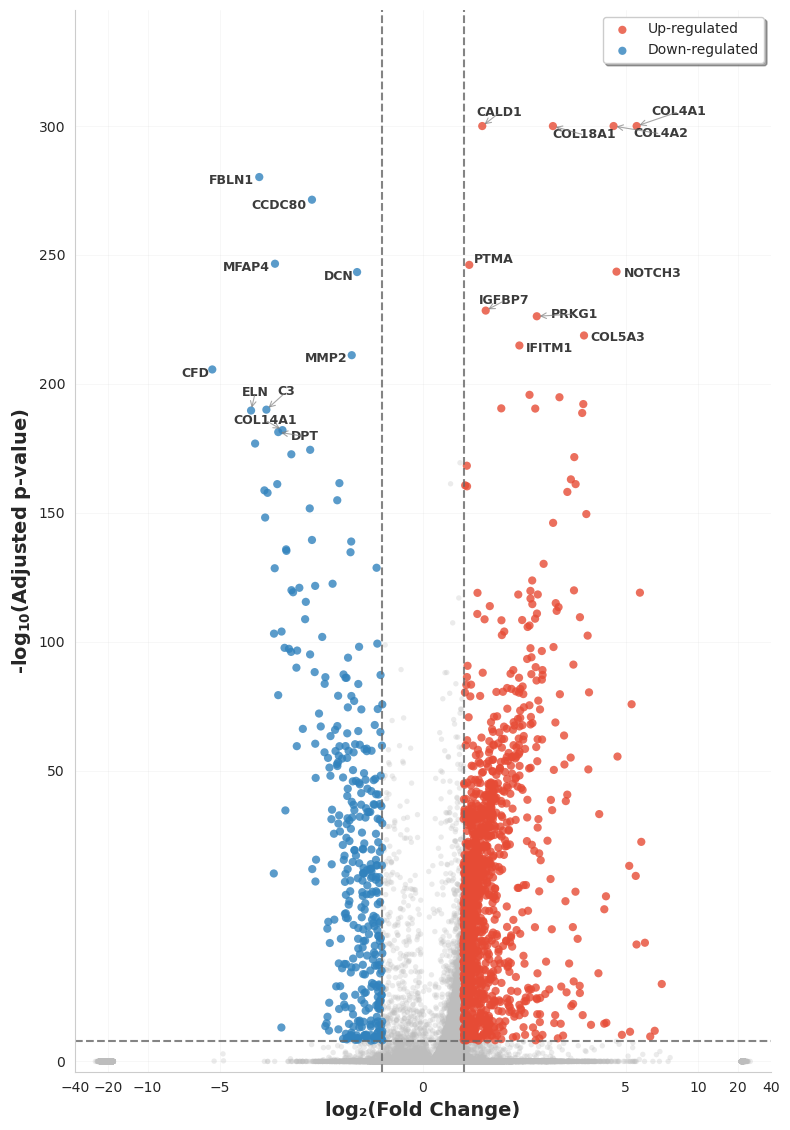

In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from adjustText import adjust_text
import matplotlib.transforms as transforms
from matplotlib.scale import FuncScale, register_scale
from matplotlib.ticker import FixedLocator, FixedFormatter

# Set constants - modify base here
LOG_BASE = 10

input_path = "./h5ad/adata_fibroblast.h5ad"
feature = "celltype"

# Set plot style
plt.style.use('default')
sns.set_style("whitegrid")

# Load data and perform differential expression analysis
adata = sc.read(input_path)

adata_raw = adata
sc.pp.normalize_total(adata_raw, target_sum=1e6)
sc.pp.log1p(adata_raw)
sc.tl.rank_genes_groups(adata_raw, feature, method='wilcoxon')

# Extract differential expression results
def extract_deg_results(adata, group):
    """Extract differential expression results for a specific group"""
    result = pd.DataFrame({
        'gene': adata.uns['rank_genes_groups']['names'][group],
        'log2fc': adata.uns['rank_genes_groups']['logfoldchanges'][group],
        'pvals': adata.uns['rank_genes_groups']['pvals'][group],
        'pvals_adj': adata.uns['rank_genes_groups']['pvals_adj'][group],
        'scores': adata.uns['rank_genes_groups']['scores'][group]
    })
    # Use constant LOG_BASE
    result[f'-log{LOG_BASE}(pval_adj)'] = -np.log(result['pvals_adj'] + 1e-300) / np.log(LOG_BASE)
    return result

# Custom x-axis scale class, compressing values beyond ±5
class CustomXScale(FuncScale):
    name = 'custom_x'
    
    def __init__(self, axis, **kwargs):
        # Forward transform: data -> display coordinates
        forward = lambda x: np.where(
            np.abs(x) <= 5,
            x,
            np.where(
                x > 5,
                5 + np.log(x - 4),  # Compress values above 5
                -5 - np.log(-x - 4)  # Compress values below -5
            )
        )
        
        # Inverse transform: display coordinates -> data
        inverse = lambda x: np.where(
            np.abs(x) <= 5,
            x,
            np.where(
                x > 5,
                4 + np.exp(x - 5),
                -4 - np.exp(-x - 5)
            )
        )
        
        super().__init__(axis, functions=(forward, inverse))

# Dynamic y-axis scale class
class DynamicYScale(FuncScale):
    name = 'dynamic_y'
    
    def __init__(self, axis, y_data, **kwargs):
        # Calculate quantiles
        q50 = np.percentile(y_data, 50)
        q75 = np.percentile(y_data, 75)
        q100 = np.max(y_data)
        
        # Use default values if no significant DEGs
        if q50 == q75 == q100 == 0:
            q50, q75, q100 = 20, 40, 60
        
        # Forward transform: data -> display coordinates
        def forward(y):
            return np.where(
                y <= q50,
                y,
                np.where(
                    y <= q75,
                    q50 + (y - q50) * 0.5,  # Compress 50%~75% by half
                    q50 + (q75 - q50) * 0.5 + (y - q75) * 0.25  # Compress 75%~100% to 1/4
                )
            )
        
        # Inverse transform: display coordinates -> data
        def inverse(y):
            return np.where(
                y <= q50,
                y,
                np.where(
                    y <= q50 + (q75 - q50) * 0.5,
                    q50 + (y - q50) * 2,
                    q75 + (y - (q50 + (q75 - q50) * 0.5)) * 4
                )
            )
        
        super().__init__(axis, functions=(forward, inverse))

# Register custom scales
register_scale(CustomXScale)
register_scale(DynamicYScale)

t = "Vascular Smooth Muscle Cell"

deg_df = extract_deg_results(adata_raw, t)
    
# Set significance thresholds
log2fc_threshold = 1.0
pval_threshold = 0.01
    
# Label significantly differentially expressed genes
deg_df['significance'] = 'Not significant'
deg_df.loc[(deg_df['log2fc'] > log2fc_threshold) & (deg_df['pvals_adj'] < pval_threshold), 'significance'] = 'Up-regulated'
deg_df.loc[(deg_df['log2fc'] < -log2fc_threshold) & (deg_df['pvals_adj'] < pval_threshold), 'significance'] = 'Down-regulated'
    
# Create volcano plot
fig, ax = plt.subplots(figsize=(8, 12))
    
# Apply custom x-axis scale
ax.set_xscale('custom_x')
    
# Only plot significantly differentially expressed genes
colors = {
    'Up-regulated': '#E64B35',
    'Down-regulated': '#3182BD',
    'Not significant': '#BDBDBD'
}
    
# Filter significant genes
significant_genes = deg_df[deg_df['significance'] != 'Not significant']
non_significant_genes = deg_df[deg_df['significance'] == 'Not significant']
    
# Get y-axis data for dynamic scale
y_data = significant_genes[f'-log{LOG_BASE}(pval_adj)'].values if len(significant_genes) > 0 else np.array([0])
    
# Apply dynamic y-axis scale
ax.set_yscale('dynamic_y', y_data=y_data)
    
# Plot non-significant genes (gray background)
ax.scatter(
        non_significant_genes['log2fc'], 
        non_significant_genes[f'-log{LOG_BASE}(pval_adj)'],
        c=colors['Not significant'],
        alpha=0.3,
        s=15,
        edgecolors='none'
    )
    
# Plot significant genes
for sig_type in ['Up-regulated', 'Down-regulated']:
    mask = significant_genes['significance'] == sig_type
    if sum(mask) > 0:
        ax.scatter(
                significant_genes.loc[mask, 'log2fc'], 
                significant_genes.loc[mask, f'-log{LOG_BASE}(pval_adj)'],
                c=colors[sig_type],
                alpha=0.8,
                s=35,
                edgecolors='none',
                label=sig_type
            )
    
# Add threshold lines
threshold_line_y = -np.log(pval_threshold) / np.log(LOG_BASE)
ax.axhline(y=threshold_line_y, color='#666666', linestyle='--', alpha=0.8, linewidth=1.5)
ax.axvline(x=log2fc_threshold, color='#666666', linestyle='--', alpha=0.8, linewidth=1.5)
ax.axvline(x=-log2fc_threshold, color='#666666', linestyle='--', alpha=0.8, linewidth=1.5)
    
# Set title and labels
ax.set_xlabel('log₂(Fold Change)', fontsize=14, fontweight='bold')
ax.set_ylabel(f'-log$_{{\\mathbf{{{LOG_BASE}}}}}$(Adjusted p-value)', fontsize=14, fontweight='bold')
    
# Add legend
ax.legend(loc='upper right', frameon=True, fancybox=True, shadow=True)
    
# Set custom tick labels
x_ticks = [-40, -20, -10, -5, 0, 5, 10, 20, 40]
ax.set_xticks(x_ticks)
    
# Label top genes
if len(significant_genes) > 0:
    up_genes = significant_genes[significant_genes['log2fc'] > 0].nsmallest(10, 'pvals_adj')
    down_genes = significant_genes[significant_genes['log2fc'] < 0].nsmallest(10, 'pvals_adj')
        
    texts = []
        
    for _, row in up_genes.iterrows():
        texts.append(ax.text(
                row['log2fc'], 
                row[f'-log{LOG_BASE}(pval_adj)'],
                row['gene'],
                fontsize=9,
                fontweight='bold',
                alpha=0.9,
                ha='left',
                va='center'
            ))
        
    for _, row in down_genes.iterrows():
        texts.append(ax.text(
                row['log2fc'], 
                row[f'-log{LOG_BASE}(pval_adj)'],
                row['gene'],
                fontsize=9,
                fontweight='bold',
                alpha=0.9,
                ha='right',
                va='center'
            ))
        
    adjust_text(texts, 
                arrowprops=dict(arrowstyle='->', color='gray', lw=0.8, alpha=0.7),
                ax=ax,
                expand_points=(1.5, 1.5),
                expand_text=(1.5, 1.5),
                force_points=(0.3, 0.6),
                force_text=(0.3, 0.6),
                lim=1500)

    
# Set axis limits
if len(significant_genes) > 0:
    x_data = significant_genes['log2fc']
    y_data = significant_genes[f'-log{LOG_BASE}(pval_adj)']
        
    # Ensure x-axis covers all data points
    x_min_data = x_data.min()
    x_max_data = x_data.max()
    x_min = min(x_min_data, -40)
    x_max = max(x_max_data, 40)
        
    # Extend if data range is larger
    if x_min_data < -40:
        x_min = x_min_data * 1.1
    if x_max_data > 40:
        x_max = x_max_data * 1.1
        
    # Calculate y-axis maximum
    y_max_data = y_data.max()
    y_max = max(y_max_data, threshold_line_y + 10)
        
    # Leave 15% margin at the top
    y_margin = y_max * 0.15
    y_upper_limit = y_max + y_margin
        
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(-1, y_upper_limit)  # Add upper space
        
else:
    # Set default range if no significant genes, leaving upper space
    ax.set_xlim(-40, 40)
    ax.set_ylim(-1, 55)  # Increased from 50 to 55 for upper margin
    
# Beautify the plot
ax.grid(True, alpha=0.2, linestyle='-', linewidth=0.5)
sns.despine()
    
# Add statistical information
n_up = sum(deg_df['significance'] == 'Up-regulated')
n_down = sum(deg_df['significance'] == 'Down-regulated')
    
# Adjust layout - use compact layout but preserve upper space
plt.tight_layout(rect=[0, 0, 1, 0.95])  # Reserve 5% space at top
    
plt.show()